# Importing Libraries

In [1]:
# !pip install torch==1.8.0
import numpy as np
import torch
import time
import torch.utils.data
from torch.utils.data.dataset import Dataset
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import random

# Importing Dataset and Training settings
## Please DO NOT change this part

In [2]:
print(f'Pytorch version: {torch.__version__}')
print(f'cuda version: {torch.version.cuda}')
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

Pytorch version: 2.6.0+cu124
cuda version: 12.4
cuda


In [3]:
def START_seed():
    seed = 66
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

epochs=30

## Load data

In [4]:
CLASSES = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [5]:
train_batch_size = 64
test_batch_size = 64
START_seed()

#train_transform = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.ToTensor()])
train_transform = transforms.Compose([transforms.ToTensor()])

test_transform = transforms.Compose([transforms.ToTensor()])

train_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)

train_loader = torch.utils.data.DataLoader(dataset=train_set, batch_size=train_batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_set, batch_size=test_batch_size, shuffle=False)

100%|██████████| 170M/170M [00:03<00:00, 43.1MB/s]


## Visualizing Data

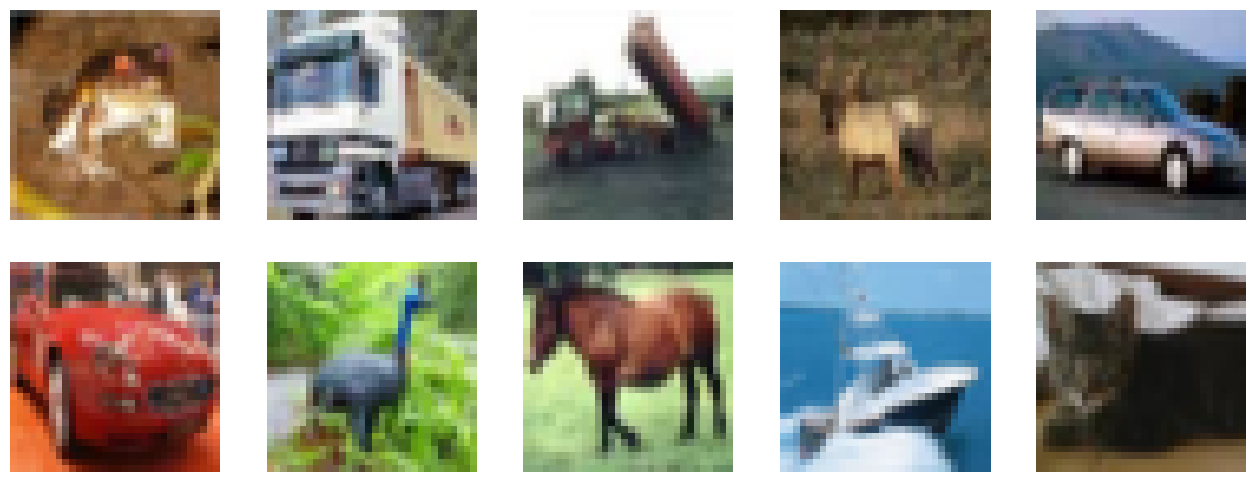

In [6]:
# show some images
plt.figure(figsize=(16, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    image, _ = train_loader.dataset.__getitem__(i)
    plt.imshow(image.squeeze().permute(1,2,0).numpy())
    plt.axis('off');

## Creating training loop

In [8]:
# Training and evaluation functions
def train(model, device, train_loader, optimizer, criterion, epoch):
    model.train()
    total_loss = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)

        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
    print(f"Train Epoch: {epoch}, Loss: {total_loss / len(train_loader):.4f}")

def test(model, device, test_loader, criterion):
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            loss = criterion(output, target)
            test_loss += loss.item()

            pred = output.argmax(dim=1)
            correct += pred.eq(target).sum().item()

    test_loss /= len(test_loader)
    accuracy = 100. * correct / len(test_loader.dataset)
    print(f"Test: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(test_loader.dataset)} ({accuracy:.2f}%)")
    return accuracy


# Task0:
## Running the base architecture
Please run the following cells

In [9]:
class Lenet5(nn.Module):
    def __init__(self, cnn_features1=6, cnn_features2=16):
        super(Lenet5, self).__init__()
        self.cnn_features1 = cnn_features1
        self.cnn_features2 = cnn_features2

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=cnn_features1, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=cnn_features1, out_channels=cnn_features2, kernel_size=5)

        self.fc1 = nn.Linear(cnn_features2*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)




    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)

        x = self.conv2(x)

        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)

        x = x.view(-1, self.cnn_features2*5*5)

        x = self.fc1(x)

        x = F.relu(x)

        x = self.fc2(x)

        x = F.relu(x)

        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)

        return x

## Displaying Network Architecture and Number of Parameters

In [10]:
START_seed()

cnn_features1 = 6 # number of feature maps
cnn_features2 = 16
model = Lenet5(cnn_features1, cnn_features2)

# print the network summary
print(model)

pytorch_total_params = sum(p.numel() for p in  model.parameters())
print('Number of parameters: {0}'.format(pytorch_total_params))

Lenet5(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
Number of parameters: 62006


## Creating the Model and Start training

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)
model.to(device)
start = time.time()
for epoch in range(0, epochs):
    train(model, device, train_loader, optimizer, criterion, epoch)
    test(model, device, test_loader, criterion)
end = time.time()
Total_time=end-start
print('Total training and inference time is: {0}'.format(Total_time))
start = time.time()
test(model, device, test_loader, criterion)


end = time.time()
Test_time=end-start
print('Total inference time is: {0}'.format(Test_time))
Training_time=Total_time-(Test_time*epochs)
print('Total Training time is: {0}'.format(Training_time))

Train Epoch: 0, Loss: 2.3012
Test: Average loss: 2.2948, Accuracy: 1001/10000 (10.01%)
Train Epoch: 1, Loss: 2.2548
Test: Average loss: 2.1549, Accuracy: 2113/10000 (21.13%)
Train Epoch: 2, Loss: 2.0458
Test: Average loss: 1.9815, Accuracy: 2743/10000 (27.43%)
Train Epoch: 3, Loss: 1.9509
Test: Average loss: 1.8991, Accuracy: 2999/10000 (29.99%)
Train Epoch: 4, Loss: 1.8440
Test: Average loss: 1.7688, Accuracy: 3623/10000 (36.23%)
Train Epoch: 5, Loss: 1.7117
Test: Average loss: 1.6443, Accuracy: 4034/10000 (40.34%)
Train Epoch: 6, Loss: 1.6053
Test: Average loss: 1.6818, Accuracy: 3793/10000 (37.93%)
Train Epoch: 7, Loss: 1.5307
Test: Average loss: 1.6205, Accuracy: 4131/10000 (41.31%)
Train Epoch: 8, Loss: 1.4752
Test: Average loss: 1.6336, Accuracy: 4014/10000 (40.14%)
Train Epoch: 9, Loss: 1.4307
Test: Average loss: 1.4873, Accuracy: 4633/10000 (46.33%)
Train Epoch: 10, Loss: 1.3973
Test: Average loss: 1.4636, Accuracy: 4709/10000 (47.09%)
Train Epoch: 11, Loss: 1.3679
Test: Averag

# Task1:Modifying maxpooling layer



## 1.1 Please modify the following network by  changing every maxpool layer with avgpool layer

In [12]:
class Lenet5_avg(nn.Module):
    def __init__(self, cnn_features1=6, cnn_features2=16):
        super(Lenet5_avg, self).__init__()
        self.cnn_features1 = cnn_features1
        self.cnn_features2 = cnn_features2

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=cnn_features1, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=cnn_features1, out_channels=cnn_features2, kernel_size=5)

        self.fc1 = nn.Linear(cnn_features2*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)




    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = F.avg_pool2d(x, kernel_size=2)

        x = self.conv2(x)

        x = F.relu(x)
        x = F.avg_pool2d(x, kernel_size=2)

        x = x.view(-1, self.cnn_features2*5*5)

        x = self.fc1(x)

        x = F.relu(x)

        x = self.fc2(x)

        x = F.relu(x)

        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)

        return x

## Displaying Network Architecture and Number of Parameters

In [13]:
START_seed()

cnn_features1 = 6 # number of feature maps
cnn_features2 = 16
model = Lenet5_avg(cnn_features1, cnn_features2)

# print the network summary
print(model)

pytorch_total_params = sum(p.numel() for p in  model.parameters())
print('Number of parameters: {0}'.format(pytorch_total_params))

Lenet5_avg(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
Number of parameters: 62006


## Creating the Model and optimizer and Starting training

In [14]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)
model.to(device)

start = time.time()
for epoch in range(0, epochs):
    train(model, device, train_loader, optimizer, criterion, epoch)
    test(model, device, test_loader, criterion)

end = time.time()
Total_time=end-start
print('Total training and inference time is: {0}'.format(Total_time))
start = time.time()
test(model, device, test_loader, criterion)


end = time.time()
Test_time=end-start
print('Total inference time is: {0}'.format(Test_time))
Training_time=Total_time-(Test_time*epochs)
print('Total Training time is: {0}'.format(Training_time))

Train Epoch: 0, Loss: 2.3015
Test: Average loss: 2.2958, Accuracy: 1024/10000 (10.24%)
Train Epoch: 1, Loss: 2.2547
Test: Average loss: 2.1638, Accuracy: 1817/10000 (18.17%)
Train Epoch: 2, Loss: 2.0509
Test: Average loss: 1.9761, Accuracy: 2845/10000 (28.45%)
Train Epoch: 3, Loss: 1.9484
Test: Average loss: 1.9326, Accuracy: 2971/10000 (29.71%)
Train Epoch: 4, Loss: 1.8727
Test: Average loss: 1.8155, Accuracy: 3486/10000 (34.86%)
Train Epoch: 5, Loss: 1.7930
Test: Average loss: 1.7571, Accuracy: 3692/10000 (36.92%)
Train Epoch: 6, Loss: 1.7215
Test: Average loss: 1.8176, Accuracy: 3342/10000 (33.42%)
Train Epoch: 7, Loss: 1.6619
Test: Average loss: 1.6352, Accuracy: 4137/10000 (41.37%)
Train Epoch: 8, Loss: 1.6062
Test: Average loss: 1.7453, Accuracy: 3705/10000 (37.05%)
Train Epoch: 9, Loss: 1.5538
Test: Average loss: 1.5447, Accuracy: 4394/10000 (43.94%)
Train Epoch: 10, Loss: 1.5101
Test: Average loss: 1.6715, Accuracy: 4047/10000 (40.47%)
Train Epoch: 11, Loss: 1.4720
Test: Averag

## 1.2 please modify the following network by removing maxpool layers and utlize convolutions with stride >1
Number of parameters must be the same as it was in base architecture

In [15]:
class Lenet5_no_pooling(nn.Module):
    def __init__(self, cnn_features1=6, cnn_features2=16):
        super(Lenet5_no_pooling, self).__init__()
        self.cnn_features1 = cnn_features1
        self.cnn_features2 = cnn_features2

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=cnn_features1, kernel_size=5, stride=2)
        self.conv2 = nn.Conv2d(in_channels=cnn_features1, out_channels=cnn_features2, kernel_size=5, stride=2)

        self.fc1 = nn.Linear(cnn_features2*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)




    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        # x = F.max_pool2d(x, kernel_size=2)

        x = self.conv2(x)

        x = F.relu(x)
        # x = F.max_pool2d(x, kernel_size=2)

        x = x.view(-1, self.cnn_features2*5*5)

        x = self.fc1(x)

        x = F.relu(x)

        x = self.fc2(x)

        x = F.relu(x)

        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)

        return x

## Displaying Network Architecture and Number of Parameters

In [16]:
START_seed()

cnn_features1 = 6 # number of feature maps
cnn_features2 = 16
model = Lenet5_no_pooling(cnn_features1, cnn_features2)

# print the network summary
print(model)

pytorch_total_params = sum(p.numel() for p in  model.parameters())
print('Number of parameters: {0}'.format(pytorch_total_params))

Lenet5_no_pooling(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(2, 2))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(2, 2))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
Number of parameters: 62006


## Creating the Model and optimizer and Starting training

In [17]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)
model.to(device)

start = time.time()
for epoch in range(0, epochs):
    train(model, device, train_loader, optimizer, criterion, epoch)
    test(model, device, test_loader, criterion)

end = time.time()
Total_time=end-start
print('Total training and inference time is: {0}'.format(Total_time))
start = time.time()
test(model, device, test_loader, criterion)


end = time.time()
Test_time=end-start
print('Total inference time is: {0}'.format(Test_time))
Training_time=Total_time-(Test_time*epochs)
print('Total Training time is: {0}'.format(Training_time))

Train Epoch: 0, Loss: 2.3010
Test: Average loss: 2.2935, Accuracy: 1032/10000 (10.32%)
Train Epoch: 1, Loss: 2.2433
Test: Average loss: 2.1455, Accuracy: 1898/10000 (18.98%)
Train Epoch: 2, Loss: 2.0509
Test: Average loss: 1.9765, Accuracy: 2793/10000 (27.93%)
Train Epoch: 3, Loss: 1.9459
Test: Average loss: 1.9208, Accuracy: 2970/10000 (29.70%)
Train Epoch: 4, Loss: 1.8702
Test: Average loss: 1.8279, Accuracy: 3437/10000 (34.37%)
Train Epoch: 5, Loss: 1.7951
Test: Average loss: 1.7551, Accuracy: 3672/10000 (36.72%)
Train Epoch: 6, Loss: 1.7330
Test: Average loss: 1.8253, Accuracy: 3327/10000 (33.27%)
Train Epoch: 7, Loss: 1.6752
Test: Average loss: 1.6797, Accuracy: 3826/10000 (38.26%)
Train Epoch: 8, Loss: 1.6184
Test: Average loss: 1.7908, Accuracy: 3524/10000 (35.24%)
Train Epoch: 9, Loss: 1.5692
Test: Average loss: 1.5778, Accuracy: 4271/10000 (42.71%)
Train Epoch: 10, Loss: 1.5325
Test: Average loss: 1.8037, Accuracy: 3713/10000 (37.13%)
Train Epoch: 11, Loss: 1.5015
Test: Averag

# Task2:Adding Dropout to the Base Network
### Please modify the following network by introducing dropout layer(s)
### dropout documentation link:https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html

In [18]:
class Lenet5_dropout(nn.Module):
    def __init__(self, cnn_features1=6, cnn_features2=16):
        super(Lenet5_dropout, self).__init__()
        self.cnn_features1 = cnn_features1
        self.cnn_features2 = cnn_features2

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=cnn_features1, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=cnn_features1, out_channels=cnn_features2, kernel_size=5)

        self.fc1 = nn.Linear(cnn_features2*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

        # Dropout layers (only applied during training)
        self.dropout1 = nn.Dropout(p=0.5)
        self.dropout2 = nn.Dropout(p=0.5)




    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)

        x = self.conv2(x)

        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)

        x = x.view(-1, self.cnn_features2*5*5)

        x = self.fc1(x)
        x = F.relu(x)
        x = self.dropout1(x)

        x = self.fc2(x)
        x = F.relu(x)
        x = self.dropout2(x)

        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)

        return x

## Displaying Network Architecture and Number of Parameters

In [19]:
START_seed()

cnn_features1 = 6 # number of feature maps
cnn_features2 = 16
model = Lenet5_dropout(cnn_features1, cnn_features2)

# print the network summary
print(model)

pytorch_total_params = sum(p.numel() for p in  model.parameters())
print('Number of parameters: {0}'.format(pytorch_total_params))

Lenet5_dropout(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
  (dropout1): Dropout(p=0.5, inplace=False)
  (dropout2): Dropout(p=0.5, inplace=False)
)
Number of parameters: 62006


## Creating the Model and optimizer and Starting training

In [20]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)
model.to(device)

start = time.time()
for epoch in range(0, epochs):
    train(model, device, train_loader, optimizer, criterion, epoch)
    test(model, device, test_loader, criterion)

end = time.time()
Total_time=end-start
print('Total training and inference time is: {0}'.format(Total_time))
start = time.time()
test(model, device, test_loader, criterion)


end = time.time()
Test_time=end-start
print('Total inference time is: {0}'.format(Test_time))
Training_time=Total_time-(Test_time*epochs)
print('Total Training time is: {0}'.format(Training_time))

Train Epoch: 0, Loss: 2.3022
Test: Average loss: 2.2977, Accuracy: 1009/10000 (10.09%)
Train Epoch: 1, Loss: 2.2853
Test: Average loss: 2.2393, Accuracy: 1821/10000 (18.21%)
Train Epoch: 2, Loss: 2.1826
Test: Average loss: 2.1049, Accuracy: 2201/10000 (22.01%)
Train Epoch: 3, Loss: 2.1005
Test: Average loss: 2.0445, Accuracy: 2389/10000 (23.89%)
Train Epoch: 4, Loss: 2.0516
Test: Average loss: 1.9733, Accuracy: 2557/10000 (25.57%)
Train Epoch: 5, Loss: 2.0019
Test: Average loss: 1.9094, Accuracy: 2936/10000 (29.36%)
Train Epoch: 6, Loss: 1.9294
Test: Average loss: 1.8783, Accuracy: 3132/10000 (31.32%)
Train Epoch: 7, Loss: 1.8642
Test: Average loss: 1.8309, Accuracy: 3487/10000 (34.87%)
Train Epoch: 8, Loss: 1.8152
Test: Average loss: 1.8198, Accuracy: 3431/10000 (34.31%)
Train Epoch: 9, Loss: 1.7677
Test: Average loss: 1.6391, Accuracy: 4021/10000 (40.21%)
Train Epoch: 10, Loss: 1.7179
Test: Average loss: 1.6881, Accuracy: 3962/10000 (39.62%)
Train Epoch: 11, Loss: 1.6802
Test: Averag

# Task3:Adding Batchnorm Layer(s) to the Base Network
### Please modify the following architecture by introducing BN layers
### You may change batch size, learning rate and/or momentum
### Batch normalization documentation link:
https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html

In [21]:
START_seed()
train_batch_size = 64 #try different batch sizes
train_loader = torch.utils.data.DataLoader(dataset=train_set, batch_size=train_batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_set, batch_size=test_batch_size, shuffle=False)

In [22]:
class Lenet5_BN(nn.Module):
    def __init__(self, cnn_features1=6, cnn_features2=16):
        super(Lenet5_BN, self).__init__()
        self.cnn_features1 = cnn_features1
        self.cnn_features2 = cnn_features2

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=cnn_features1, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=cnn_features1, out_channels=cnn_features2, kernel_size=5)

        self.fc1 = nn.Linear(cnn_features2*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

        self.bn1 = nn.BatchNorm2d(cnn_features1)
        self.bn2 = nn.BatchNorm2d(cnn_features2)
        self.bn3 = nn.BatchNorm1d(120)
        self.bn4 = nn.BatchNorm1d(84)




    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)

        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)

        x = x.view(-1, self.cnn_features2*5*5)

        x = self.fc1(x)
        x = self.bn3(x)
        x = F.relu(x)

        x = self.fc2(x)
        x = self.bn4(x)
        x = F.relu(x)

        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)

        return x

## Displaying Network Architecture and Number of Parameters

In [23]:
START_seed()

cnn_features1 = 6 # number of feature maps
cnn_features2 = 16
model = Lenet5_BN(cnn_features1, cnn_features2)

# print the network summary
print(model)

pytorch_total_params = sum(p.numel() for p in  model.parameters())
print('Number of parameters: {0}'.format(pytorch_total_params))

Lenet5_BN(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
  (bn1): BatchNorm2d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn3): BatchNorm1d(120, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn4): BatchNorm1d(84, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)
Number of parameters: 62458


## Creating the Model and optimizer and Starting training

In [24]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)
model.to(device)

start = time.time()
for epoch in range(0, epochs):
    train(model, device, train_loader, optimizer, criterion, epoch)
    test(model, device, test_loader, criterion)

end = time.time()
Total_time=end-start
print('Total training and inference time is: {0}'.format(Total_time))
start = time.time()
test(model, device, test_loader, criterion)


end = time.time()
Test_time=end-start
print('Total inference time is: {0}'.format(Test_time))
Training_time=Total_time-(Test_time*epochs)
print('Total Training time is: {0}'.format(Training_time))

Train Epoch: 0, Loss: 1.7063
Test: Average loss: 1.5439, Accuracy: 4424/10000 (44.24%)
Train Epoch: 1, Loss: 1.4042
Test: Average loss: 1.6460, Accuracy: 4077/10000 (40.77%)
Train Epoch: 2, Loss: 1.2837
Test: Average loss: 1.6046, Accuracy: 4577/10000 (45.77%)
Train Epoch: 3, Loss: 1.2030
Test: Average loss: 1.5775, Accuracy: 4677/10000 (46.77%)
Train Epoch: 4, Loss: 1.1353
Test: Average loss: 1.3143, Accuracy: 5263/10000 (52.63%)
Train Epoch: 5, Loss: 1.0812
Test: Average loss: 1.8740, Accuracy: 4224/10000 (42.24%)
Train Epoch: 6, Loss: 1.0321
Test: Average loss: 2.0258, Accuracy: 4045/10000 (40.45%)
Train Epoch: 7, Loss: 0.9909
Test: Average loss: 1.3564, Accuracy: 5374/10000 (53.74%)
Train Epoch: 8, Loss: 0.9556
Test: Average loss: 1.3383, Accuracy: 5354/10000 (53.54%)
Train Epoch: 9, Loss: 0.9230
Test: Average loss: 1.1347, Accuracy: 6066/10000 (60.66%)
Train Epoch: 10, Loss: 0.8942
Test: Average loss: 1.6892, Accuracy: 4449/10000 (44.49%)
Train Epoch: 11, Loss: 0.8684
Test: Averag

# Task4: Applying Dropout and Batch normalization on the base network
## Please modify the following network by adding both dropout and batch normalization layer/s

In [25]:
class Lenet5_Drop_BN(nn.Module):
    def __init__(self, cnn_features1=6, cnn_features2=16):
        super(Lenet5_Drop_BN, self).__init__()
        self.cnn_features1 = cnn_features1
        self.cnn_features2 = cnn_features2

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=cnn_features1, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=cnn_features1, out_channels=cnn_features2, kernel_size=5)

        self.fc1 = nn.Linear(cnn_features2*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

        self.bn1 = nn.BatchNorm2d(cnn_features1)
        self.bn2 = nn.BatchNorm2d(cnn_features2)
        self.bn3 = nn.BatchNorm1d(120)
        self.bn4 = nn.BatchNorm1d(84)

        self.dropout1 = nn.Dropout(p=0.5)
        self.dropout2 = nn.Dropout(p=0.5)



    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)

        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)

        x = x.view(-1, self.cnn_features2*5*5)

        x = self.fc1(x)
        x = self.bn3(x)
        x = F.relu(x)
        x = self.dropout1(x)

        x = self.fc2(x)
        x = self.bn4(x)
        x = F.relu(x)
        x = self.dropout2(x)

        x = self.fc3(x)
        x = F.log_softmax(x, dim=1)

        return x

## Displaying Network Architecture and Number of Parameters

In [26]:
START_seed()

cnn_features1 = 6 # number of feature maps
cnn_features2 = 16
model = Lenet5_Drop_BN(cnn_features1, cnn_features2)

# print the network summary
print(model)

pytorch_total_params = sum(p.numel() for p in  model.parameters())
print('Number of parameters: {0}'.format(pytorch_total_params))

Lenet5_Drop_BN(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
  (bn1): BatchNorm2d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn3): BatchNorm1d(120, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn4): BatchNorm1d(84, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout1): Dropout(p=0.5, inplace=False)
  (dropout2): Dropout(p=0.5, inplace=False)
)
Number of parameters: 62458


## Creating the Model and optimizer and Starting training

In [27]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)
model.to(device)

start = time.time()
for epoch in range(0, epochs):
    train(model, device, train_loader, optimizer, criterion, epoch)
    test(model, device, test_loader, criterion)

end = time.time()
Total_time=end-start
print('Total training and inference time is: {0}'.format(Total_time))
start = time.time()
test(model, device, test_loader, criterion)


end = time.time()
Test_time=end-start
print('Total inference time is: {0}'.format(Test_time))
Training_time=Total_time-(Test_time*epochs)
print('Total Training time is: {0}'.format(Training_time))

Train Epoch: 0, Loss: 1.9588
Test: Average loss: 1.8283, Accuracy: 3364/10000 (33.64%)
Train Epoch: 1, Loss: 1.6914
Test: Average loss: 2.2537, Accuracy: 2409/10000 (24.09%)
Train Epoch: 2, Loss: 1.5965
Test: Average loss: 1.4929, Accuracy: 4678/10000 (46.78%)
Train Epoch: 3, Loss: 1.5347
Test: Average loss: 1.4041, Accuracy: 4929/10000 (49.29%)
Train Epoch: 4, Loss: 1.4911
Test: Average loss: 1.6910, Accuracy: 4050/10000 (40.50%)
Train Epoch: 5, Loss: 1.4486
Test: Average loss: 1.3621, Accuracy: 5154/10000 (51.54%)
Train Epoch: 6, Loss: 1.4090
Test: Average loss: 1.9799, Accuracy: 3699/10000 (36.99%)
Train Epoch: 7, Loss: 1.3817
Test: Average loss: 2.1589, Accuracy: 3462/10000 (34.62%)
Train Epoch: 8, Loss: 1.3547
Test: Average loss: 1.8200, Accuracy: 3920/10000 (39.20%)
Train Epoch: 9, Loss: 1.3341
Test: Average loss: 1.5772, Accuracy: 4319/10000 (43.19%)
Train Epoch: 10, Loss: 1.3111
Test: Average loss: 1.7866, Accuracy: 4039/10000 (40.39%)
Train Epoch: 11, Loss: 1.2940
Test: Averag

# Main Task:
# T5. One Network to Best Them All
### Using the previous observations and what you learned in the lecture please modify the following architecture to achieve best possible accuracy.
Examples of architectural changes to the baseline: adding more convolutional layers, more channels perconvolution layer, more fully connected layers, dropout, BN, data-augmentations, etc

# Add Your Augmentations
to read more about the availabe augmentations check the documentation:https://pytorch.org/vision/stable/transforms.html

In [ ]:
START_seed()

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2023, 0.1994, 0.2010))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2023, 0.1994, 0.2010))
])

train_batch_size=512  #choose your batch size

train_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)

train_loader = torch.utils.data.DataLoader(dataset=train_set, batch_size=train_batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_set, batch_size=test_batch_size, shuffle=False)

## Modify the Base Model

In [122]:
import torch.nn as nn
import torch.nn.functional as F

class Yournet(nn.Module):
    def __init__(self):
        super(Yournet, self).__init__()

        self.conv1 = nn.Conv2d(3, 23, kernel_size=5, padding=1)
        self.bn1 = nn.BatchNorm2d(23)

        self.conv2 = nn.Conv2d(23, 40, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(40)

        self.conv3 = nn.Conv2d(40, 80, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(80)

        self.conv4 = nn.Conv2d(80, 85, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(85)

        self.skip_conv = nn.Conv2d(40, 85, kernel_size=1)

        self.pool = nn.MaxPool2d(2, 2)
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        self.fc1 = nn.Linear(85, 160)
        self.bn_fc1 = nn.BatchNorm1d(160)
        self.drop_fc1 = nn.Dropout(0.4)

        self.fc2 = nn.Linear(160, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))  # -> [16, 16, 16]
        x = self.pool(F.relu(self.bn2(self.conv2(x))))  # -> [32, 8, 8]

        residual = self.skip_conv(x)  # -> [64, 8, 8]

        x = F.relu(self.bn3(self.conv3(x)))             # -> [64, 8, 8]
        x = self.bn4(self.conv4(x))                     # -> [64, 8, 8]

        x += residual
        x = F.relu(x)

        x = self.gap(x).view(x.size(0), -1)             # -> [batch, 64]
        x = self.drop_fc1(F.relu(self.bn_fc1(self.fc1(x))))  # -> [batch, 128]
        x = self.fc2(x)
        return F.log_softmax(x, dim=1)

## Displaying Network Architecture and Number of Parameters

In [121]:
START_seed()

# Hyperparameters
cnn_features1 = 10
cnn_features2 = 20
epochs = 30
learning_rate = 0.02
momentum = 0.9

# Init model
# model = Yournet(cnn_features1=cnn_features1, cnn_features2=cnn_features2)
model = Yournet()

# Print summary
print(model)
pytorch_total_params = sum(p.numel() for p in model.parameters())
print('Number of parameters: {0}'.format(pytorch_total_params))


Yournet(
  (conv1): Conv2d(3, 23, kernel_size=(5, 5), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(23, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(23, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(40, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(80, 85, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(85, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (skip_conv): Conv2d(40, 85, kernel_size=(1, 1), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc1): Linear(in_features=85, out_features=160, bias=True)
  (bn_fc1): BatchNorm1d(160, eps=1e-05, momentum=0.1, affine=True, tra

## Training

In [101]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate, momentum=momentum)
model.to(device)

start = time.time()
for epoch in range(epochs):
    train(model, device, train_loader, optimizer, criterion, epoch)
    test(model, device, test_loader, criterion)
end = time.time()

Total_time = end - start
print('Total training and inference time is: {:.2f} seconds'.format(Total_time))

start = time.time()
test(model, device, test_loader, criterion)
end = time.time()

Test_time = end - start
print('Total inference time is: {:.2f} seconds'.format(Test_time))

Training_time = Total_time - (Test_time * epochs)
print('Total training time is: {:.2f} seconds'.format(Training_time))

Train Epoch: 0, Average Loss: 1.7200
Test: Average loss: 1.6334, Accuracy: 4164/10000 (41.64%)


Train Epoch: 1, Average Loss: 1.3864
Test: Average loss: 1.4076, Accuracy: 5204/10000 (52.04%)


Train Epoch: 2, Average Loss: 1.2396
Test: Average loss: 1.3578, Accuracy: 5311/10000 (53.11%)


Train Epoch: 3, Average Loss: 1.1459
Test: Average loss: 1.2109, Accuracy: 5723/10000 (57.23%)


Train Epoch: 4, Average Loss: 1.0779
Test: Average loss: 1.1680, Accuracy: 5954/10000 (59.54%)


...

Train Epoch: 25, Average Loss: 0.6229
Test: Average loss: 0.6296, Accuracy: 7873/10000 (78.73%)


Train Epoch: 26, Average Loss: 0.6124
Test: Average loss: 0.5915, Accuracy: 8002/10000 (80.02%)


Train Epoch: 27, Average Loss: 0.6037
Test: Average loss: 0.5521, Accuracy: 8074/10000 (80.74%)


Train Epoch: 28, Average Loss: 0.5978
Test: Average loss: 0.6069, Accuracy: 7926/10000 (79.26%)


Train Epoch: 29, Average Loss: 0.5890
Test: Average loss: 0.5876, Accuracy: 8006/10000 (80.06%)
Total training and inference time is: 1258.17 seconds
Test: Average loss: 0.5876, Accuracy: 8006/10000 (80.06%)
Total inference time is: 2.13 seconds
Total training time is: 1194.35 seconds
